# 1. Set up the notebook

Do imports.

In [2]:
import numpy as np
import sympy as sym
from scipy import linalg
import json
import matplotlib.pyplot as plt
from ae483.tools import *
from ae483.mytools import *

Check mocap coverage from `lab07_square01.json`.

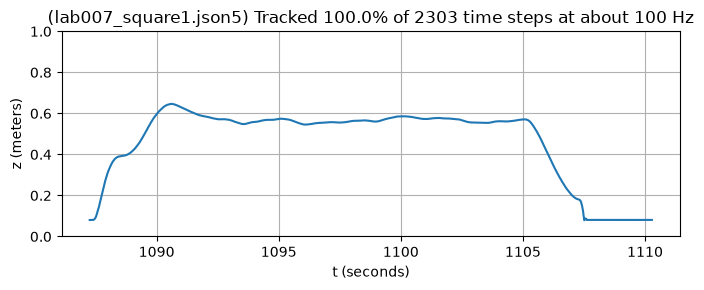

In [3]:
check_mocap_coverage('lab007_square1.json5')

# 2. Derive models

## 2.1 Define symbolic variables

Define states.

In [4]:
# components of position (meters)
p_x, p_y, p_z = sym.symbols('p_x, p_y, p_z')

# yaw, pitch, and roll angles (radians)
psi, theta, phi = sym.symbols('psi, theta, phi')

# components of linear velocity (meters / second)
v_x, v_y, v_z = sym.symbols('v_x, v_y, v_z')

Define inputs.

In [5]:
# gyroscope measurements - components of angular velocity (radians / second)
w_x, w_y, w_z = sym.symbols('w_x, w_y, w_z')

# z-axis accelerometer measurement - specific force (meters / second^2)
a_z = sym.symbols('a_z')

Define outputs.

In [6]:
n_x, n_y, r = sym.symbols('n_x, n_y, r')

Define parameters.

In [7]:
g, k_flow = sym.symbols('g, k_flow')

Create the linear velocity vector $v^B_{W, B}$ and the angular velocity vector $w^B_{W, B}$, both written in the coordinates of the body frame.

In [8]:
v_inB_ofWB = sym.Matrix([v_x, v_y, v_z])
w_inB_ofWB = sym.Matrix([w_x, w_y, w_z])

## 2.2 Define kinematics of orientation

### 2.2.1 Rotation matrix in terms of yaw, pitch, roll angles

Define individual rotation matrices.

In [9]:
Rz = sym.Matrix([[sym.cos(psi), -sym.sin(psi), 0],
                 [sym.sin(psi), sym.cos(psi), 0],
                 [0, 0, 1]])

Ry = sym.Matrix([[sym.cos(theta), 0, sym.sin(theta)],
                 [0, 1, 0],
                 [-sym.sin(theta), 0, sym.cos(theta)]])

Rx = sym.Matrix([[1, 0, 0],
                 [0, sym.cos(phi), -sym.sin(phi)],
                 [0, sym.sin(phi), sym.cos(phi)]])

Apply sequential transformation to compute the rotation matrix that describes the orientation of the drone (i.e., of frame $B$ in the coordinates of frame $W$).

In [10]:
R_inW_ofB = Rz @ Ry @ Rx

### 2.2.2 Map from angular velocity to angular rates

Recall that

$$\begin{bmatrix} \dot{\psi} \\ \dot{\theta} \\ \dot{\phi} \end{bmatrix} = N w_{W, B}^{B}$$

for some matrix $N$. Here is how to compute that matrix for a ZYX (yaw, pitch, roll) Euler angle sequence.  First, we compute its inverse:

In [11]:
Ninv = sym.Matrix.hstack((Ry @ Rx).T @ sym.Matrix([[0], [0], [1]]),
                              (Rx).T @ sym.Matrix([[0], [1], [0]]),
                                       sym.Matrix([[1], [0], [0]]))

Then, we compute $N$ by taking the inverse of $N^{-1}$:

In [12]:
N = sym.simplify(Ninv.inv())

## 2.3 Derive equations of motion

Define $a^\text{SF}$, i.e., "acceleration without the gravity term."

In [13]:
aSF = sym.Matrix([
    w_inB_ofWB.cross(v_inB_ofWB)[0],
    w_inB_ofWB.cross(v_inB_ofWB)[1],
    a_z,
])

Create equations of motion.

In [14]:
f = sym.Matrix.vstack(
    R_inW_ofB @ v_inB_ofWB,
    N @ w_inB_ofWB,
    R_inW_ofB.T @ sym.Matrix([0, 0, - g]) + aSF,
)

Show equations of motion, which have the form

$$\dot{s} = f(s, i, p)$$

where

$$
s = \begin{bmatrix} o_x \\ o_y \\ o_z \\ \psi \\ \theta \\ \phi \\ v_x \\ v_y \\ v_z \end{bmatrix}
\qquad\qquad
i = \begin{bmatrix} w_x \\ w_y \\ w_z \\ a_z \end{bmatrix}
\qquad\qquad
p = \begin{bmatrix} g \\ k_\text{flow} \end{bmatrix}.
$$

In [15]:
f

Matrix([
[ v_x*cos(psi)*cos(theta) + v_y*(sin(phi)*sin(theta)*cos(psi) - sin(psi)*cos(phi)) + v_z*(sin(phi)*sin(psi) + sin(theta)*cos(phi)*cos(psi))],
[v_x*sin(psi)*cos(theta) + v_y*(sin(phi)*sin(psi)*sin(theta) + cos(phi)*cos(psi)) + v_z*(-sin(phi)*cos(psi) + sin(psi)*sin(theta)*cos(phi))],
[                                                                       -v_x*sin(theta) + v_y*sin(phi)*cos(theta) + v_z*cos(phi)*cos(theta)],
[                                                                                         w_y*sin(phi)/cos(theta) + w_z*cos(phi)/cos(theta)],
[                                                                                                               w_y*cos(phi) - w_z*sin(phi)],
[                                                                                   w_x + w_y*sin(phi)*tan(theta) + w_z*cos(phi)*tan(theta)],
[                                                                                                          g*sin(theta) - v_y*w_z + v_z*w_y

## 2.4 Derive measurement equations

Create measurement equations.

In [16]:
h = sym.Matrix([
    k_flow * (v_x - p_z * w_y) / p_z,        # <-- x flow (n_x)
    k_flow * (v_y + p_z * w_x) / p_z,        # <-- y flow (n_y)
    p_z / (sym.cos(phi) * sym.cos(theta)),   # <-- z range (r)
])

Show measurement equations, which have the form

$$o = h(s, i, p)$$

where

$$
o = \begin{bmatrix} n_x \\ n_y \\ r \end{bmatrix}
\qquad\qquad
s = \begin{bmatrix} o_x \\ o_y \\ o_z \\ \psi \\ \theta \\ \phi \\ v_x \\ v_y \\ v_z \end{bmatrix}
\qquad\qquad
i = \begin{bmatrix} w_x \\ w_y \\ w_z \\ a_z \end{bmatrix}
\qquad\qquad
p = \begin{bmatrix} g \\ k_\text{flow} \end{bmatrix}.
$$

In [17]:
h

Matrix([
[k_flow*(-p_z*w_y + v_x)/p_z],
[ k_flow*(p_z*w_x + v_y)/p_z],
[  p_z/(cos(phi)*cos(theta))]])

# 3. Derive state-space model

## 3.1 Choose equilibrium point

An equilibrium point of the nonlinear system is a choice of states $s_\text{eq}$ and inputs $i_\text{eq}$ — along with constant parameters $p_\text{eq}$ — for which

$$0 = f(s_\text{eq}, i_\text{eq}, p_\text{eq}).$$

Create a symbolic variable to describe the equilibrium value of $p_z$.

In [18]:
p_z_eq = sym.symbols('p_z_eq')

Create a list of states, inputs, outputs, and parameters as symbolic variables.

In [19]:
s = [p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z]
i = [w_x, w_y, w_z, a_z]
o = [n_x, n_y, r]
p = [g, k_flow]

Create a list of state and input values at equilibrium in the **same order** as before.

In [20]:
s_eq = [0, 0, p_z_eq, 0, 0, 0, 0, 0, 0]
i_eq = [0, 0, 0, g]

Make sure all equilibrium values are symbolic.

In [21]:
s_eq = [sym.nsimplify(a) for a in s_eq]
i_eq = [sym.nsimplify(a) for a in i_eq]

Evaluate the equations of motion at the equilibrium point - if it actually *is* an equilibrium point, then the result should be a matrix of zeros:

In [22]:
f.subs(tuple(zip(s, s_eq))).subs(tuple(zip(i, i_eq)))

Matrix([
[0],
[0],
[0],
[0],
[0],
[0],
[0],
[0],
[0]])

## 3.2 Find $A$, $B$, $C$, and $D$

Recall that:

$$
A = \frac{\partial f}{\partial s}\biggr\vert_{(s, i, p) = (s_\text{eq}, i_\text{eq}, p_\text{eq})}
\qquad\quad
B = \frac{\partial f}{\partial i}\biggr\vert_{(s, i, p) = (s_\text{eq}, i_\text{eq}, p_\text{eq})}
\qquad\quad
C = \frac{\partial h}{\partial s}\biggr\vert_{(s, i, p) = (s_\text{eq}, i_\text{eq}, p_\text{eq})}
\qquad\quad
D = \frac{\partial h}{\partial i}\biggr\vert_{(s, i, p) = (s_\text{eq}, i_\text{eq}, p_\text{eq})}.
$$

Compute each Jacobian and plug in the equilibrium values as follows.

In [23]:
A = f.jacobian(s).subs(tuple(zip(s, s_eq))).subs(tuple(zip(i, i_eq)))
B = f.jacobian(i).subs(tuple(zip(s, s_eq))).subs(tuple(zip(i, i_eq)))
C = h.jacobian(s).subs(tuple(zip(s, s_eq))).subs(tuple(zip(i, i_eq)))
D = h.jacobian(i).subs(tuple(zip(s, s_eq))).subs(tuple(zip(i, i_eq)))

Show $A$:

In [24]:
A

Matrix([
[0, 0, 0, 0, 0,  0, 1, 0, 0],
[0, 0, 0, 0, 0,  0, 0, 1, 0],
[0, 0, 0, 0, 0,  0, 0, 0, 1],
[0, 0, 0, 0, 0,  0, 0, 0, 0],
[0, 0, 0, 0, 0,  0, 0, 0, 0],
[0, 0, 0, 0, 0,  0, 0, 0, 0],
[0, 0, 0, 0, g,  0, 0, 0, 0],
[0, 0, 0, 0, 0, -g, 0, 0, 0],
[0, 0, 0, 0, 0,  0, 0, 0, 0]])

Show $B$:

In [25]:
B

Matrix([
[0, 0, 0, 0],
[0, 0, 0, 0],
[0, 0, 0, 0],
[0, 0, 1, 0],
[0, 1, 0, 0],
[1, 0, 0, 0],
[0, 0, 0, 0],
[0, 0, 0, 0],
[0, 0, 0, 1]])

Show $C$:

In [26]:
C

Matrix([
[0, 0, 0, 0, 0, 0, k_flow/p_z_eq,             0, 0],
[0, 0, 0, 0, 0, 0,             0, k_flow/p_z_eq, 0],
[0, 0, 1, 0, 0, 0,             0,             0, 0]])

Show $D$ (note that it is *not* zero in this case):

In [27]:
D

Matrix([
[     0, -k_flow, 0, 0],
[k_flow,       0, 0, 0],
[     0,       0, 0, 0]])

## 3.3 Write linearized models

Define the state, input, and output of the state-space system (i.e., the linearized model of the equations of motion and of the measurement equations).

In [28]:
x = sym.Matrix(s) - sym.Matrix(s_eq)
u = sym.Matrix(i) - sym.Matrix(i_eq)
y = sym.Matrix(o) - h.subs(tuple(zip(s, s_eq))).subs(tuple(zip(i, i_eq)))

Show the linearized equations of motion $Ax+Bu$.

In [29]:
A @ x + B @ u

Matrix([
[    v_x],
[    v_y],
[    v_z],
[    w_z],
[    w_y],
[    w_x],
[g*theta],
[ -g*phi],
[a_z - g]])

Show the linearized measurement equations $Cx+Du$.

In [30]:
C @ x + D @ u

Matrix([
[-k_flow*w_y + k_flow*v_x/p_z_eq],
[ k_flow*w_x + k_flow*v_y/p_z_eq],
[                   p_z - p_z_eq]])

Show the output (which our model tells us should be $Cx+Du$).

In [31]:
y

Matrix([
[        n_x],
[        n_y],
[-p_z_eq + r]])

# 4. Study error in linearized models

## 4.1 Load and parse flight data

Flight was visually good, but its ahrd to tell without parsing the flight data first. But from visual inspection it formed a complete square and landed back at its origin point while maintaining stable flight and hover.

Load flight data.

In [32]:
# Load flight data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('lab007_square1.json5')

# Resample drone data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0., # <-- FIXME
    t_max_offset=0., # <-- FIXME
)

# Sync and resample mocap data
data_mocap = sync_data_mocap(
    raw_data_mocap,
    data_drone['time'],
    data_drone['ae483log.p_z'],
    do_transform=True,      # <-- whether to align mocap data in space (don't change this)
    t_min_offset=0.,        # <-- how many seconds of mocap data to delete at the start
    t_shift_rng=1.,         # <-- range of time shifts over which to search
    t_shift_res=0.05,       # <-- resolution at which to sample time shifts in the range
)

# Only look at data from when the drone was actually flying
only_in_flight(data_drone, data_mocap=data_mocap)

Parse flight data.

In [33]:
# Drone data
# time
t = data_drone['time']
# states
p_x = data_drone['ae483log.p_x']
p_y = data_drone['ae483log.p_y']
p_z = data_drone['ae483log.p_z']
psi = data_drone['ae483log.psi']
theta = data_drone['ae483log.theta']
phi = data_drone['ae483log.phi']
v_x = data_drone['ae483log.v_x']
v_y = data_drone['ae483log.v_y']
v_z = data_drone['ae483log.v_z']
# inputs
w_x = data_drone['ae483log.w_x']
w_y = data_drone['ae483log.w_y']
w_z = data_drone['ae483log.w_z']
a_z = data_drone['ae483log.a_z']
# outputs
n_x = data_drone['ae483log.n_x']
n_y = data_drone['ae483log.n_y']
r = data_drone['ae483log.r']

# Mocap data
p_x_mocap = data_mocap['x']
p_y_mocap = data_mocap['y']
p_z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

Find time step (should be 0.01).

In [34]:
dt = t[1] - t[0]
print(f'dt = {dt:.4f}')
assert(np.isclose(dt, 0.01))

dt = 0.0100


Define numerical values of each parameter.

**Choice of $p_{z,\text{eq}}$:** We cannot choose $p_{z,\text{eq}} = 0$, because $p_z$ appears in the denominator of the linearized optical flow measurement equations (e.g., $n_x \approx k_\text{flow}\left(\dfrac{v_x}{p_{z,\text{eq}}} - w_y\right)$), so $p_{z,\text{eq}} = 0$ would make $C$ (and $D$) undefined (division by zero, giving infinite entries).

Instead, we choose $p_{z,\text{eq}} = 0.5\,\text{m}$. In the flight that produced our data, the drone took off to $0.2\,\text{m}$, climbed to $0.5\,\text{m}$, flew the entire square ($0.5\,\text{m}$ on a side) at a constant height of $0.5\,\text{m}$, then descended back to $0.2\,\text{m}$ and landed. The drone spent most of the flight — and essentially all of the time it was moving horizontally, which is when the optical flow measurements matter most — at $p_z \approx 0.5\,\text{m}$. Linearizing about this height therefore minimizes the error in the linearized measurement equations (in particular the $v_x/p_z$ and $v_y/p_z$ terms, and the $p_z$ term in the ToF measurement) over this trajectory.

In [35]:
# Acceleration of gravity
g = 9.81

# Optical flow constant (do not modify)
k_flow = 0.01 * 30.0 / np.deg2rad(4.2)

# Equilibrium value of p_z
p_z_eq = 0.5    # <-- height (m) at which the square was flown

## 4.2 Error in linearized equations of motion

### 4.2.1 Error in linear model of $\dot{p}_x$

Approximate $\dot{p}_x$ by finite difference and call this "ground truth."

In [36]:
p_x_dot_true = (p_x[1:] - p_x[:-1]) / dt

Remember that, because of the way it is computed, the length of the finite difference approximation `p_x_dot_true` is one less than the length of `p_x` (and of `t`):

In [37]:
print(f'len(p_x_dot_true) = {len(p_x_dot_true)}')
print(f'         len(p_x) = {len(p_x)}')
print(f'           len(t) = {len(t)}')

len(p_x_dot_true) = 2005
         len(p_x) = 2006
           len(t) = 2006


Predict $\dot{p}_x$ with linearized equations of motion.

In particular, note that the first element of $\dot{x}$ is

$$ \dfrac{d}{dt}\left( p_x - p_{x,\text{eq}} \right) = \dot{p}_x, $$

and that the first element of $Ax+Bu$ is $v_x$. So, our state-space model tells us that $\dot{p}_x \approx v_x$.

In [38]:
p_x_dot_predicted = v_x

Compare the true value and the predicted values of $\dot{p}_x$ in a plot.

Text(0.5, 0, 'time (s)')

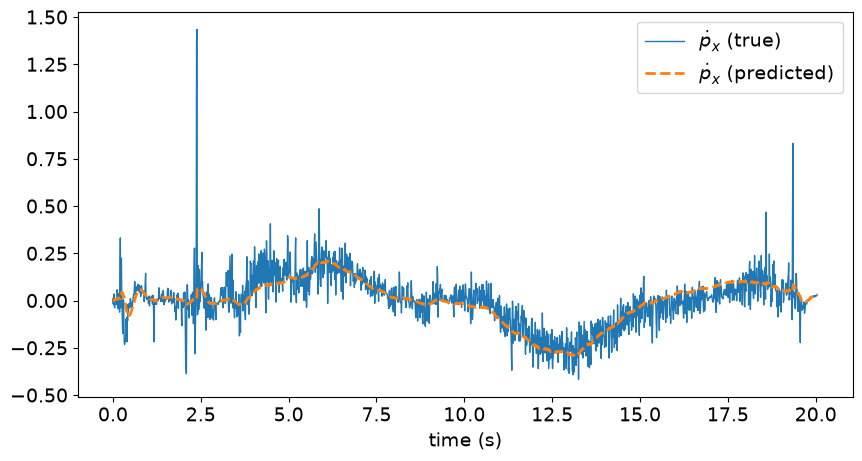

In [39]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t[:-1], p_x_dot_true, label=r'$\dot{p}_x$ (true)', linewidth=1)
ax.plot(t, p_x_dot_predicted, '--', label=r'$\dot{p}_x$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $\dot{p}_x$.

In [40]:
p_x_dot_err = p_x_dot_predicted[:-1] - p_x_dot_true

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $\\dot{p}_x$\n(mean = -0.004, std =  0.084)')

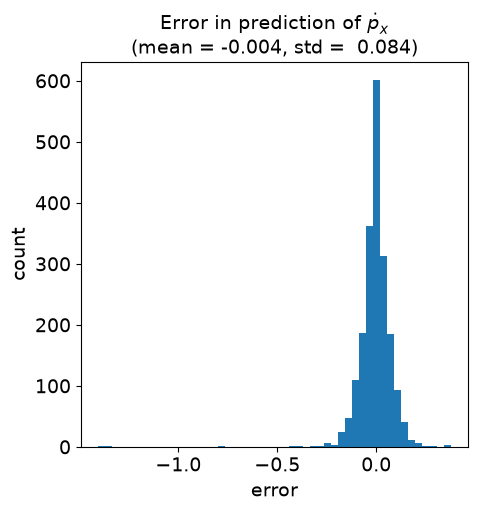

In [41]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(p_x_dot_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $\dot{p}_x$' +
    f'\n(mean = {np.mean(p_x_dot_err):6.3f}, std = {np.std(p_x_dot_err):6.3f})',
    fontsize=14,
)

### 4.2.2 Error in linear model of $\dot{p}_y$

Approximate $\dot{p}_y$ by finite difference and call this "ground truth."

In [42]:
p_y_dot_true = (p_y[1:] - p_y[:-1]) / dt

Predict $\dot{p}_y$ with linearized equations of motion.

In particular, note that the second element of $\dot{x}$ is

$$ \dfrac{d}{dt}\left( p_y - p_{y,\text{eq}} \right) = \dot{p}_y, $$

and that the second element of $Ax+Bu$ is $v_y$. So, our state-space model tells us that $\dot{p}_y \approx v_y$.

In [43]:
p_y_dot_predicted = v_y

Compare the true value and the predicted values of $\dot{p}_y$ in a plot.

Text(0.5, 0, 'time (s)')

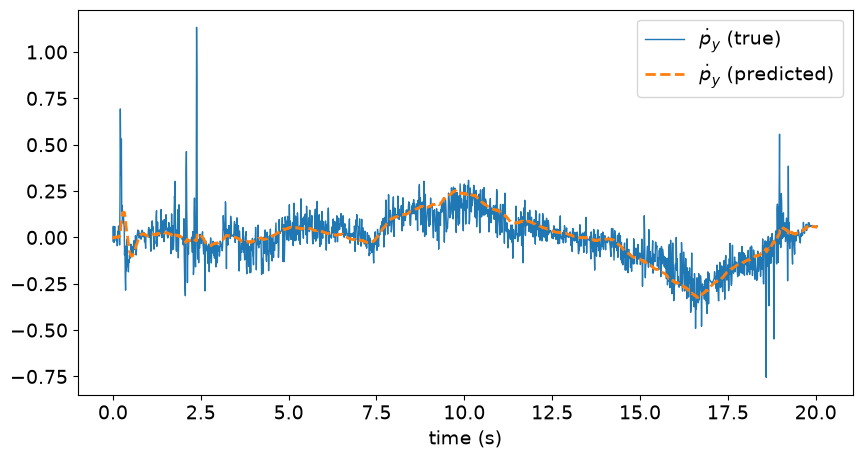

In [44]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t[:-1], p_y_dot_true, label=r'$\dot{p}_y$ (true)', linewidth=1)
ax.plot(t, p_y_dot_predicted, '--', label=r'$\dot{p}_y$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $\dot{p}_y$.

In [45]:
p_y_dot_err = p_y_dot_predicted[:-1] - p_y_dot_true

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $\\dot{p}_y$\n(mean =  0.006, std =  0.084)')

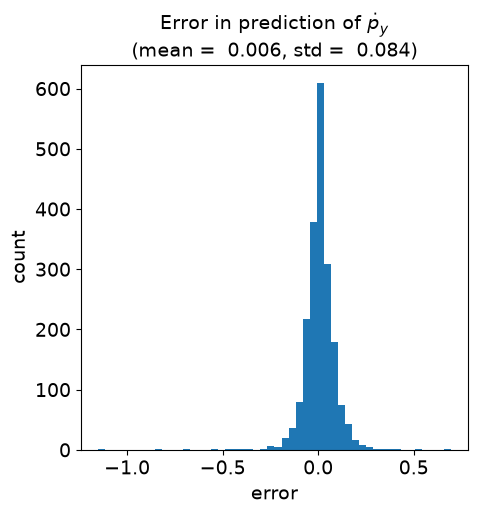

In [46]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(p_y_dot_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $\dot{p}_y$' +
    f'\n(mean = {np.mean(p_y_dot_err):6.3f}, std = {np.std(p_y_dot_err):6.3f})',
    fontsize=14,
)

### 4.2.3 Error in linear model of $\dot{p}_z$

Approximate $\dot{p}_z$ by finite difference and call this "ground truth."

In [47]:
p_z_dot_true = (p_z[1:] - p_z[:-1]) / dt

Predict $\dot{p}_z$ with linearized equations of motion.

In particular, note that the third element of $\dot{x}$ is

$$ \dfrac{d}{dt}\left( p_z - p_{z,\text{eq}} \right) = \dot{p}_z, $$

and that the third element of $Ax+Bu$ is $v_z$. So, our state-space model tells us that $\dot{p}_z \approx v_z$.

In [48]:
p_z_dot_predicted = v_z

Compare the true value and the predicted values of $\dot{p}_z$ in a plot.

Text(0.5, 0, 'time (s)')

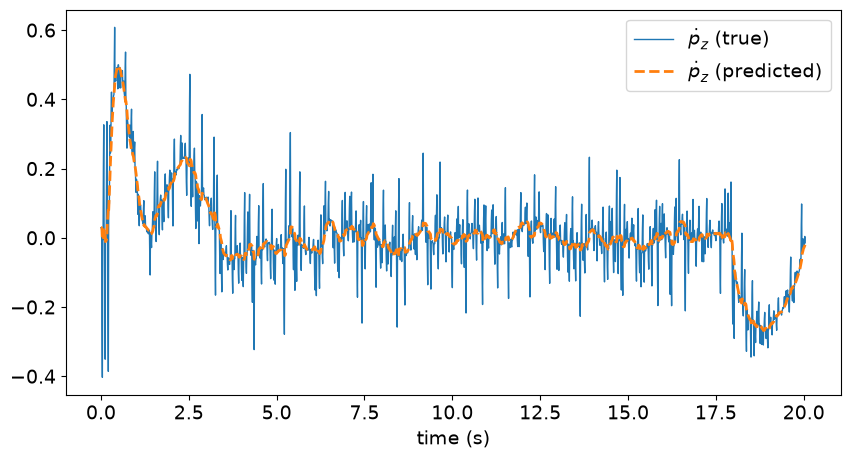

In [49]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t[:-1], p_z_dot_true, label=r'$\dot{p}_z$ (true)', linewidth=1)
ax.plot(t, p_z_dot_predicted, '--', label=r'$\dot{p}_z$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $\dot{p}_z$.

In [50]:
p_z_dot_err = p_z_dot_predicted[:-1] - p_z_dot_true

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $\\dot{p}_z$\n(mean =  0.000, std =  0.058)')

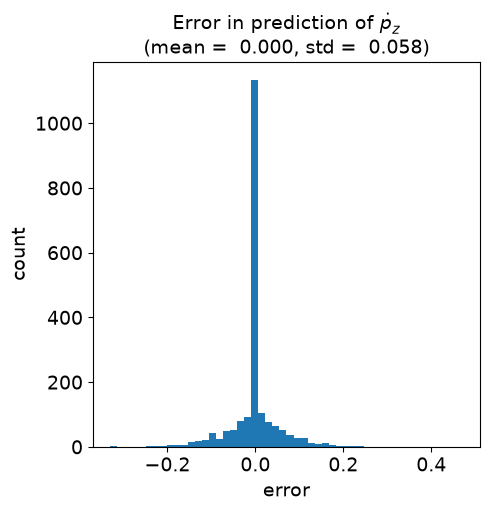

In [51]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(p_z_dot_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $\dot{p}_z$' +
    f'\n(mean = {np.mean(p_z_dot_err):6.3f}, std = {np.std(p_z_dot_err):6.3f})',
    fontsize=14,
)

### 4.2.4 Error in linear model of $\dot{\psi}$

Approximate $\dot{\psi}$ by finite difference and call this "ground truth."

In [52]:
psi_dot_true = (psi[1:] - psi[:-1]) / dt

Predict $\dot{\psi}$ with linearized equations of motion.

In particular, note that the fourth element of $\dot{x}$ is

$$ \dfrac{d}{dt}\left( \psi - \psi_\text{eq} \right) = \dot{\psi}, $$

and that the fourth element of $Ax+Bu$ is $w_z$. So, our state-space model tells us that $\dot{\psi} \approx w_z$.

In [53]:
psi_dot_predicted = w_z

Compare the true value and the predicted values of $\dot{\psi}$ in a plot.

Text(0.5, 0, 'time (s)')

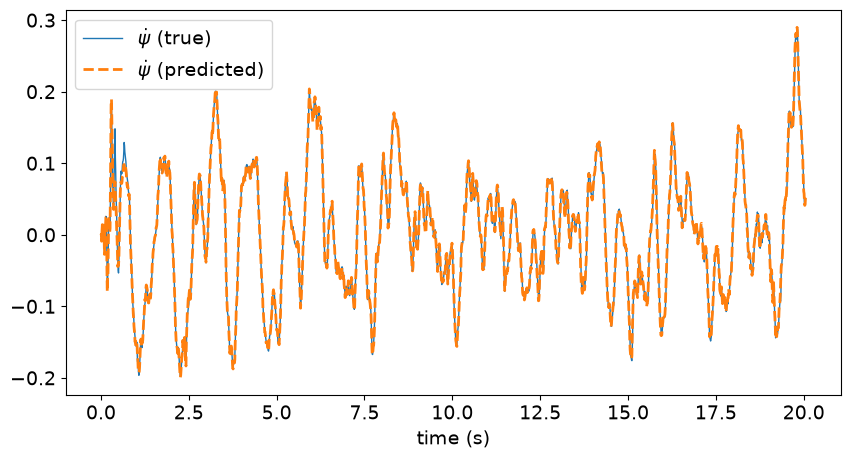

In [54]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t[:-1], psi_dot_true, label=r'$\dot{\psi}$ (true)', linewidth=1)
ax.plot(t, psi_dot_predicted, '--', label=r'$\dot{\psi}$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $\dot{\psi}$.

In [55]:
psi_dot_err = psi_dot_predicted[:-1] - psi_dot_true

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $\\dot{\\psi}$\n(mean = -0.000, std =  0.005)')

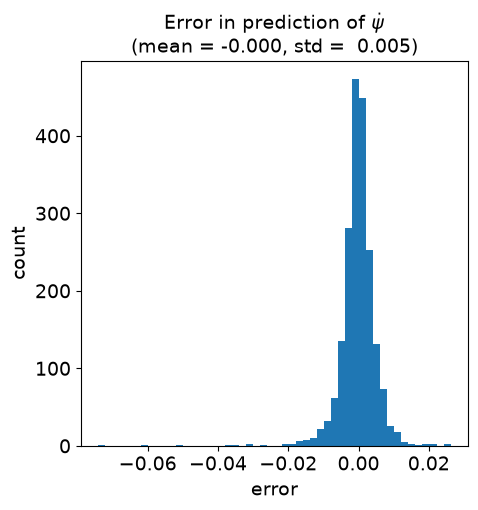

In [56]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(psi_dot_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $\dot{\psi}$' +
    f'\n(mean = {np.mean(psi_dot_err):6.3f}, std = {np.std(psi_dot_err):6.3f})',
    fontsize=14,
)

### 4.2.5 Error in linear model of $\dot{\theta}$

Approximate $\dot{\theta}$ by finite difference and call this "ground truth."

In [57]:
theta_dot_true = (theta[1:] - theta[:-1]) / dt

Predict $\dot{\theta}$ with linearized equations of motion.

In particular, note that the fifth element of $\dot{x}$ is

$$ \dfrac{d}{dt}\left( \theta - \theta_\text{eq} \right) = \dot{\theta}, $$

and that the fifth element of $Ax+Bu$ is $w_y$. So, our state-space model tells us that $\dot{\theta} \approx w_y$.

In [58]:
theta_dot_predicted = w_y

Compare the true value and the predicted values of $\dot{\theta}$ in a plot.

Text(0.5, 0, 'time (s)')

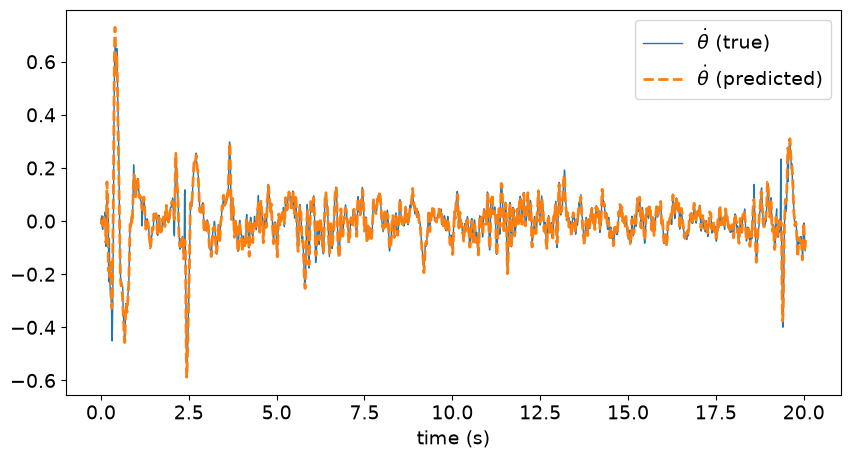

In [59]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t[:-1], theta_dot_true, label=r'$\dot{\theta}$ (true)', linewidth=1)
ax.plot(t, theta_dot_predicted, '--', label=r'$\dot{\theta}$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $\dot{\theta}$.

In [60]:
theta_dot_err = theta_dot_predicted[:-1] - theta_dot_true

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $\\dot{\\theta}$\n(mean =  0.000, std =  0.019)')

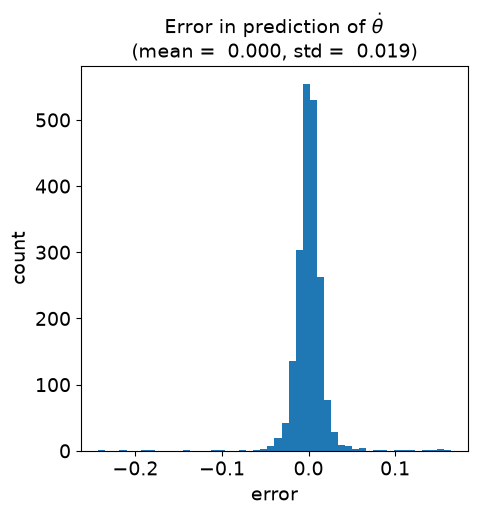

In [61]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(theta_dot_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $\dot{\theta}$' +
    f'\n(mean = {np.mean(theta_dot_err):6.3f}, std = {np.std(theta_dot_err):6.3f})',
    fontsize=14,
)

### 4.2.6 Error in linear model of $\dot{\phi}$

Approximate $\dot{\phi}$ by finite difference and call this "ground truth."

In [62]:
phi_dot_true = (phi[1:] - phi[:-1]) / dt

Predict $\dot{\phi}$ with linearized equations of motion.

In particular, note that the sixth element of $\dot{x}$ is

$$ \dfrac{d}{dt}\left( \phi - \phi_\text{eq} \right) = \dot{\phi}, $$

and that the sixth element of $Ax+Bu$ is $w_x$. So, our state-space model tells us that $\dot{\phi} \approx w_x$.

In [63]:
phi_dot_predicted = w_x

Compare the true value and the predicted values of $\dot{\phi}$ in a plot.

Text(0.5, 0, 'time (s)')

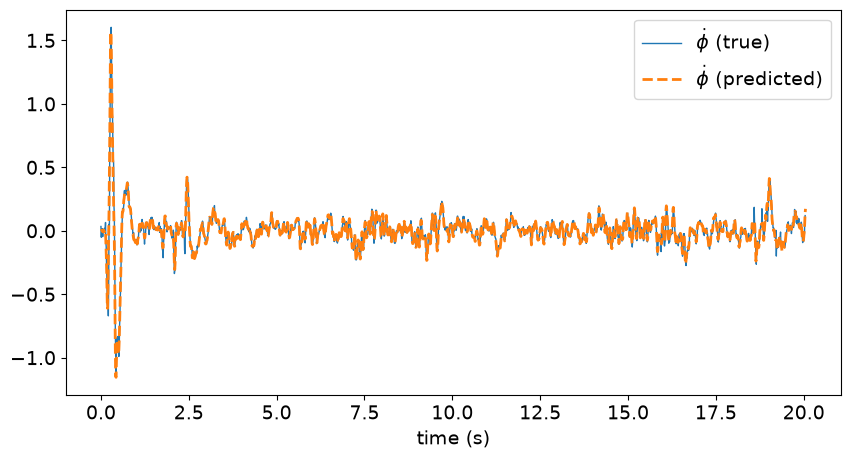

In [64]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t[:-1], phi_dot_true, label=r'$\dot{\phi}$ (true)', linewidth=1)
ax.plot(t, phi_dot_predicted, '--', label=r'$\dot{\phi}$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $\dot{\phi}$.

In [65]:
phi_dot_err = phi_dot_predicted[:-1] - phi_dot_true

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $\\dot{\\phi}$\n(mean = -0.000, std =  0.029)')

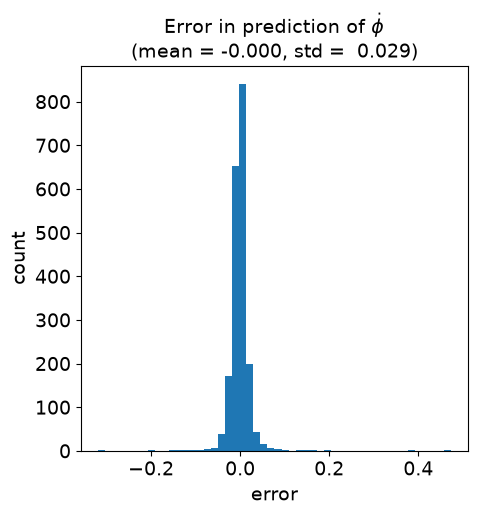

In [66]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(phi_dot_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $\dot{\phi}$' +
    f'\n(mean = {np.mean(phi_dot_err):6.3f}, std = {np.std(phi_dot_err):6.3f})',
    fontsize=14,
)

### 4.2.7 Error in linear model of $\dot{v}_x$

Approximate $\dot{v}_x$ by finite difference and call this "ground truth."

In [67]:
v_x_dot_true = (v_x[1:] - v_x[:-1]) / dt

Predict $\dot{v}_x$ with linearized equations of motion.

In particular, note that the seventh element of $\dot{x}$ is

$$ \dfrac{d}{dt}\left( v_x - v_{x,\text{eq}} \right) = \dot{v}_x, $$

and that the seventh element of $Ax+Bu$ is $g\theta$. So, our state-space model tells us that $\dot{v}_x \approx g\theta$.

In [68]:
v_x_dot_predicted = g * theta

Compare the true value and the predicted values of $\dot{v}_x$ in a plot.

Text(0.5, 0, 'time (s)')

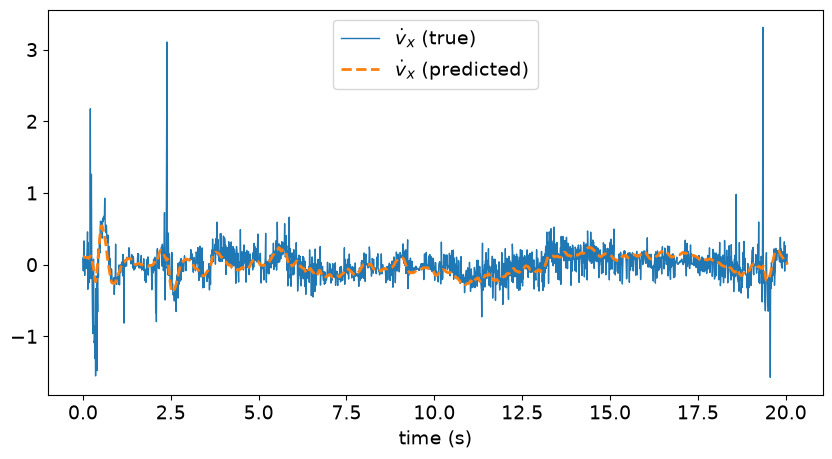

In [69]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t[:-1], v_x_dot_true, label=r'$\dot{v}_x$ (true)', linewidth=1)
ax.plot(t, v_x_dot_predicted, '--', label=r'$\dot{v}_x$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $\dot{v}_x$.

In [70]:
v_x_dot_err = v_x_dot_predicted[:-1] - v_x_dot_true

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $\\dot{v}_x$\n(mean = -0.003, std =  0.208)')

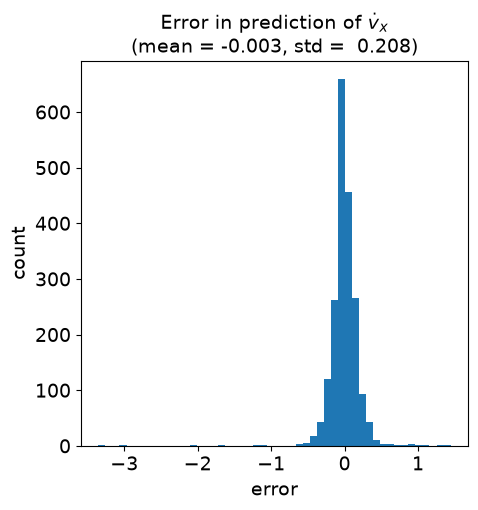

In [71]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(v_x_dot_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $\dot{v}_x$' +
    f'\n(mean = {np.mean(v_x_dot_err):6.3f}, std = {np.std(v_x_dot_err):6.3f})',
    fontsize=14,
)

### 4.2.8 Error in linear model of $\dot{v}_y$

Approximate $\dot{v}_y$ by finite difference and call this "ground truth."

In [72]:
v_y_dot_true = (v_y[1:] - v_y[:-1]) / dt

Predict $\dot{v}_y$ with linearized equations of motion.

In particular, note that the eighth element of $\dot{x}$ is

$$ \dfrac{d}{dt}\left( v_y - v_{y,\text{eq}} \right) = \dot{v}_y, $$

and that the eighth element of $Ax+Bu$ is $-g\phi$. So, our state-space model tells us that $\dot{v}_y \approx -g\phi$.

In [73]:
v_y_dot_predicted = -g * phi

Compare the true value and the predicted values of $\dot{v}_y$ in a plot.

Text(0.5, 0, 'time (s)')

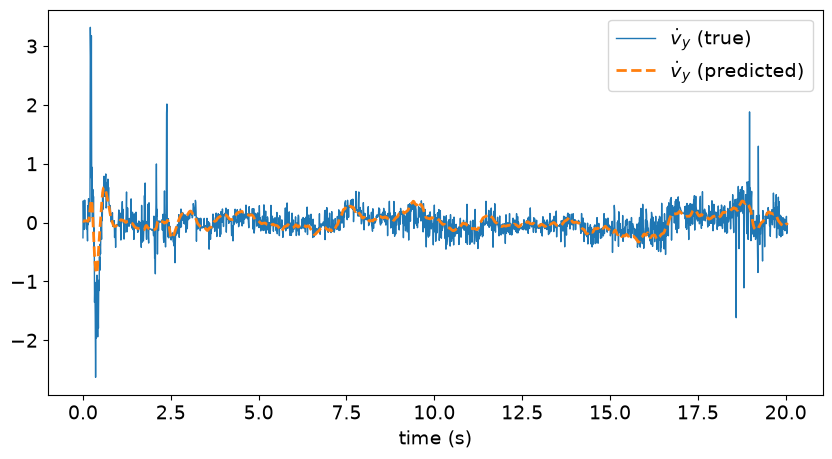

In [74]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t[:-1], v_y_dot_true, label=r'$\dot{v}_y$ (true)', linewidth=1)
ax.plot(t, v_y_dot_predicted, '--', label=r'$\dot{v}_y$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $\dot{v}_y$.

In [75]:
v_y_dot_err = v_y_dot_predicted[:-1] - v_y_dot_true

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $\\dot{v}_y$\n(mean =  0.008, std =  0.226)')

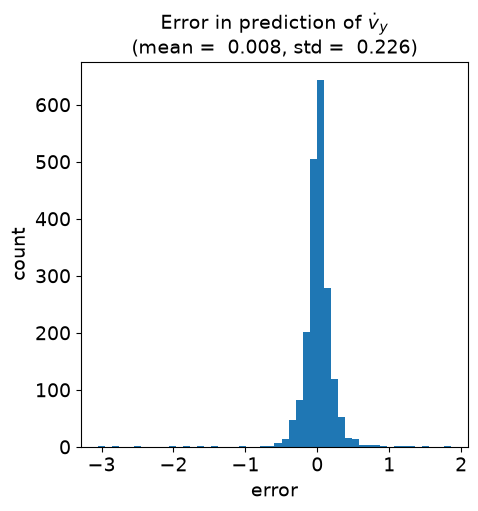

In [76]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(v_y_dot_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $\dot{v}_y$' +
    f'\n(mean = {np.mean(v_y_dot_err):6.3f}, std = {np.std(v_y_dot_err):6.3f})',
    fontsize=14,
)

### 4.2.9 Error in linear model of $\dot{v}_z$

Approximate $\dot{v}_z$ by finite difference and call this "ground truth."

In [77]:
v_z_dot_true = (v_z[1:] - v_z[:-1]) / dt

Predict $\dot{v}_z$ with linearized equations of motion.

In particular, note that the ninth element of $\dot{x}$ is

$$ \dfrac{d}{dt}\left( v_z - v_{z,\text{eq}} \right) = \dot{v}_z, $$

and that the ninth element of $Ax+Bu$ is $a_z - g$ (remember that $u_4 = a_z - a_{z,\text{eq}}$ and $a_{z,\text{eq}} = g$). So, our state-space model tells us that $\dot{v}_z \approx a_z - g$.

In [78]:
v_z_dot_predicted = a_z - g

Compare the true value and the predicted values of $\dot{v}_z$ in a plot.

Text(0.5, 0, 'time (s)')

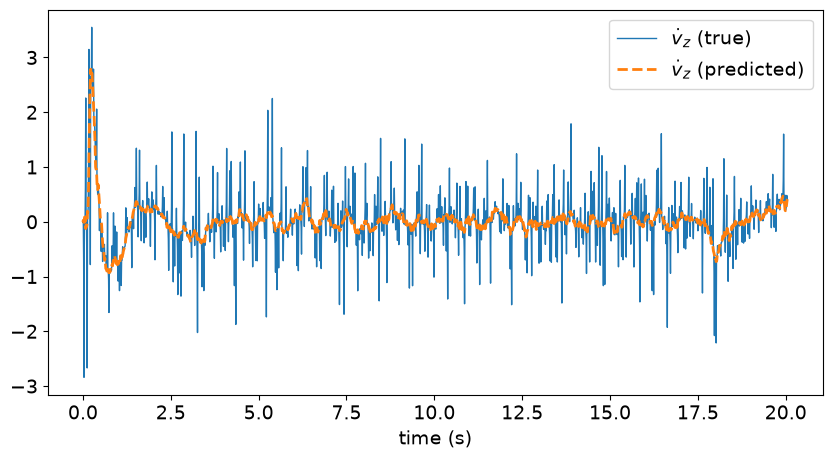

In [79]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t[:-1], v_z_dot_true, label=r'$\dot{v}_z$ (true)', linewidth=1)
ax.plot(t, v_z_dot_predicted, '--', label=r'$\dot{v}_z$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $\dot{v}_z$.

In [80]:
v_z_dot_err = v_z_dot_predicted[:-1] - v_z_dot_true

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $\\dot{v}_z$\n(mean =  0.002, std =  0.356)')

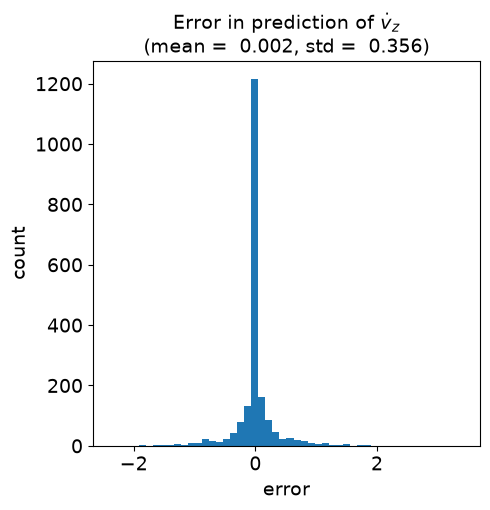

In [81]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(v_z_dot_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $\dot{v}_z$' +
    f'\n(mean = {np.mean(v_z_dot_err):6.3f}, std = {np.std(v_z_dot_err):6.3f})',
    fontsize=14,
)

## 4.3 Error in linearized measurement equations

### 4.3.1 Error in linear model of $n_x$

Predict $n_x$ with the linearized measurement equations.

In particular, note that the first element of $y$ is $n_x$, and that the first element of $Cx+Du$ is

$$k_\text{flow} \left( \dfrac{v_x}{p_\text{z, eq}} - w_y \right),$$

so our linear model tells us that

$$n_x \approx k_\text{flow} \left( \dfrac{v_x}{p_\text{z, eq}} - w_y \right).$$

In [82]:
n_x_predicted = k_flow * ((v_x / p_z_eq) - w_y)

Compare the true value and the predicted values of $n_x$ in a plot.

Text(0.5, 0, 'time (s)')

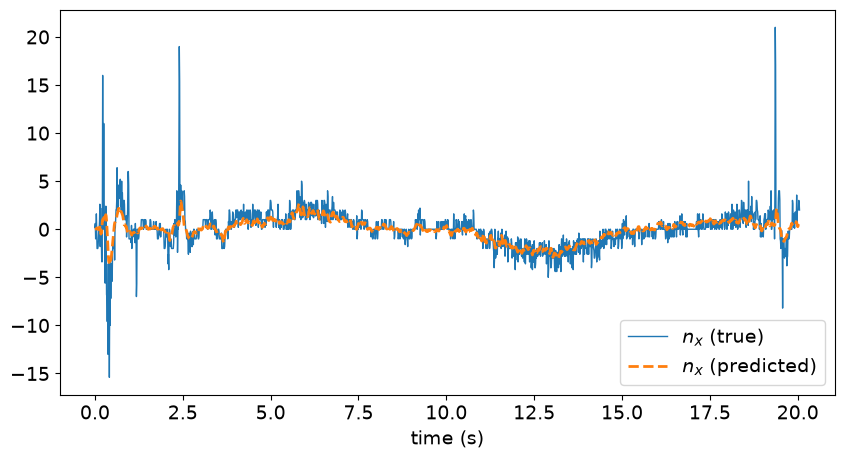

In [83]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t, n_x, label=r'$n_x$ (true)', linewidth=1)
ax.plot(t, n_x_predicted, '--', label=r'$n_x$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $n_x$.

In [84]:
n_x_err = n_x_predicted - n_x

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $n_x$\n(mean = -0.056, std =  1.420)')

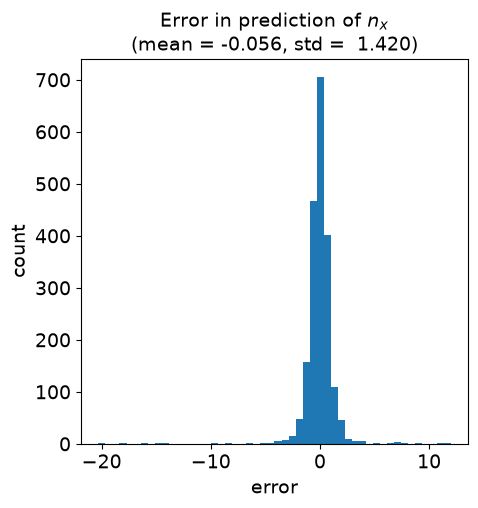

In [85]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(n_x_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $n_x$' +
    f'\n(mean = {np.mean(n_x_err):6.3f}, std = {np.std(n_x_err):6.3f})',
    fontsize=14,
)

### 4.3.2 Error in linear model of $n_y$

Predict $n_y$ with the linearized measurement equations.

In particular, note that the second element of $y$ is $n_y$, and that the second element of $Cx+Du$ is

$$k_\text{flow} \left( \dfrac{v_y}{p_\text{z, eq}} + w_x \right),$$

so our linear model tells us that

$$n_y \approx k_\text{flow} \left( \dfrac{v_y}{p_\text{z, eq}} + w_x \right).$$

In [86]:
n_y_predicted = k_flow * ((v_y / p_z_eq) + w_x)

Compare the true value and the predicted values of $n_y$ in a plot.

Text(0.5, 0, 'time (s)')

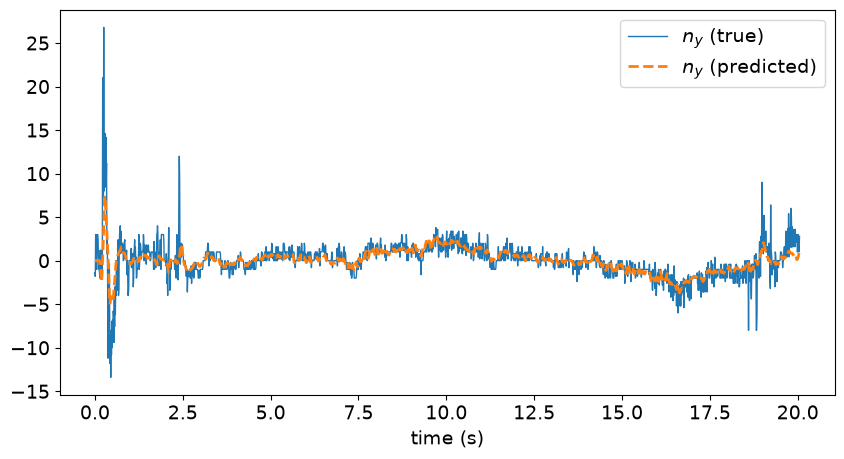

In [87]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t, n_y, label=r'$n_y$ (true)', linewidth=1)
ax.plot(t, n_y_predicted, '--', label=r'$n_y$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $n_y$.

In [88]:
n_y_err = n_y_predicted - n_y

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $n_y$\n(mean = -0.046, std =  1.512)')

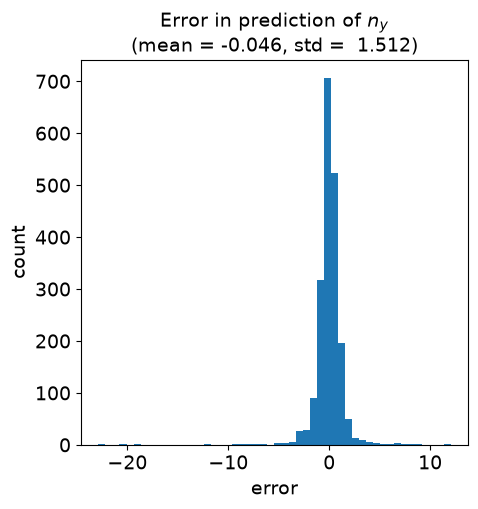

In [89]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(n_y_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $n_y$' +
    f'\n(mean = {np.mean(n_y_err):6.3f}, std = {np.std(n_y_err):6.3f})',
    fontsize=14,
)

### 4.3.3 Error in linear model of $r$

Predict $r$ with the linearized measurement equations.

In particular, note that the third element of $y$ is $r$, and that the third element of $Cx+Du$ is

$$p_z,$$

so our linear model tells us that

$$r \approx p_z.$$

In [90]:
r_predicted = p_z

Compare the true value and the predicted values of $r$ in a plot.

Text(0.5, 0, 'time (s)')

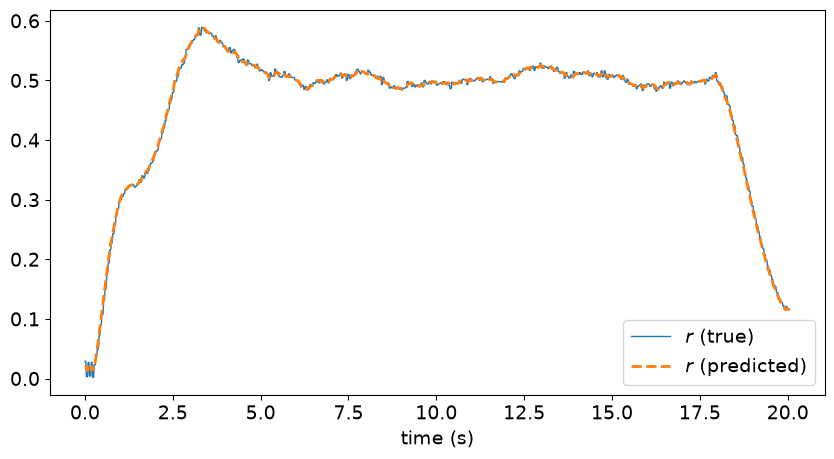

In [91]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(t, r, label=r'$r$ (true)', linewidth=1)
ax.plot(t, r_predicted, '--', label=r'$r$ (predicted)', linewidth=2)
ax.legend(fontsize=14)
ax.tick_params(labelsize=14)
ax.set_xlabel('time (s)', fontsize=14)

Compute the error in the linear model, i.e., the difference between the predicted and true values of $r$.

In [92]:
r_err = r_predicted - r

Plot a histogram of the error, showing mean and standard deviation.

Text(0.5, 1.0, 'Error in prediction of $r$\n(mean =  0.000, std =  0.003)')

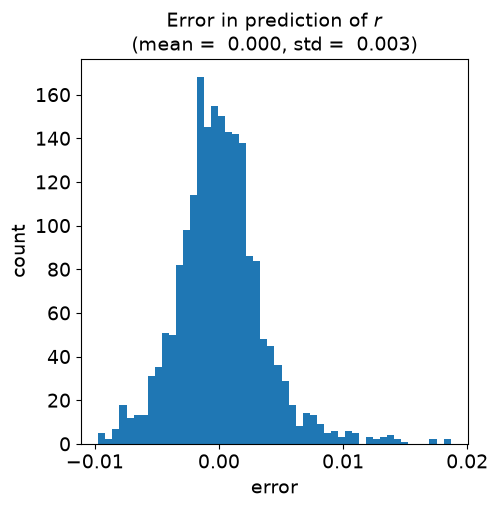

In [93]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(r_err, 50)
ax.set_xlabel('error', fontsize=14)
ax.set_ylabel('count', fontsize=14)
ax.tick_params(labelsize=14)
ax.set_title(
    r'Error in prediction of $r$' +
    f'\n(mean = {np.mean(r_err):6.3f}, std = {np.std(r_err):6.3f})',
    fontsize=14,
)

## 4.4 Summary

The following table reports the mean and standard deviation of error in the linearized equations of motion:

|  | $\dot{p}_x$ | $\dot{p}_y$ | $\dot{p}_z$ | $\dot{\psi}$ | $\dot{\theta}$ | $\dot{\phi}$ | $\dot{v}_x$ | $\dot{v}_y$ | $\dot{v}_z$ |
| :--: | :--: | :--: | :--: | :--: | :--: | :--: | :--: | :--: | :--: |
| mean | -0.004 | 0.006 | 0.000 | -0.000 | 0.000 | -0.000 | -0.003 | 0.008 | 0.002 |
| std | 0.084 | 0.084 | 0.058 | 0.005 | 0.019 | 0.029 | 0.208 | 0.226 | 0.356 |

The following table reports the mean and standard deviation of error in the linearized measurement equations:

|  | $n_x$ | $n_y$ | $r$ |
| :--: | :--: | :--: | :--: |
| mean | -0.056 | -0.046 | 0.000 |
| std | 1.420 | 1.512 | 0.003 |

**Reasoning.** Every mean error is essentially zero (much smaller than the corresponding std), so none of the models has a significant bias. The models therefore differ mainly in their standard deviation of error, and it makes sense to judge that std relative to the size of the signal being predicted (e.g., the error in $\dot{\theta}$ should be compared to typical values of $\dot{\theta}$).

**Equations of motion.**

* *Most trusted:* the attitude equations $\dot{\psi} \approx w_z$, $\dot{\theta} \approx w_y$, $\dot{\phi} \approx w_x$ (std of 0.005, 0.019, and 0.029 rad/s). These are almost exact near hover — the only approximation is that small angles decouple the body rates from the Euler angle rates — and the gyroscope measures the rates directly.
* *Next:* the position equations $\dot{p} \approx v$ (std 0.06–0.08 m/s). These are exact if yaw is zero; the remaining error comes mostly from finite-differencing noisy position estimates and small yaw/attitude rotations between body and world frames.
* *Least trusted:* the velocity equations $\dot{v}_x \approx g\theta$, $\dot{v}_y \approx -g\phi$, $\dot{v}_z \approx a_z - g$ (std 0.21–0.36 m/s², comparable to the size of the signals themselves). Here the small-angle approximation matters more, the model ignores drag and other unmodeled forces, and the "true" value is a finite difference of an already-noisy velocity estimate, which amplifies noise. $\dot{v}_z$ is worst, since the accelerometer signal $a_z$ is noisy (motor vibration) and the drone made large vertical changes during takeoff, climb, descent, and landing.

**Measurement equations.**

* *Most trusted:* $r \approx p_z$ (std 0.003 m). Near hover $\cos\phi\cos\theta \approx 1$, so this linearization is nearly exact. (One caveat: the "true" $p_z$ here is the onboard estimate, which is itself computed largely from $r$, so this comparison probably understates the real error.)
* *Least trusted:* the optical flow equations for $n_x$ and $n_y$ (std 1.42 and 1.51, a large fraction of the signals' own spread). The flow sensor is noisy, and the linearization replaces $1/p_z$ with $1/p_{z,\text{eq}}$, which is badly wrong during takeoff and landing at $p_z \approx 0.2$ m. Restricting to the part of the flight near $p_z = 0.5$ m reduces the std to about 0.97 ($n_x$) and 0.85 ($n_y$), confirming that much of the error comes from flying away from the equilibrium height.

**Conclusion.** We should trust the gyro-based attitude model and the range measurement the most, and the velocity dynamics and the optical flow measurements the least. This should be reflected in the observer weights: smaller standard deviations (larger weights) for the trusted equations and larger standard deviations (smaller weights) for $\dot{v}$ and for $n_x, n_y$.

## 5. Export state-space model

Convert the matrices $A$, $B$, $C$, and $D$ that describe the state-space model from sympy (symbolic) to numpy (numeric), substituting a value for each parameter.

In [94]:
A_num = sym.lambdify(['g', 'k_flow', 'p_z_eq'], A)(g, k_flow, p_z_eq).astype(np.float64)
B_num = sym.lambdify(['g', 'k_flow', 'p_z_eq'], B)(g, k_flow, p_z_eq).astype(np.float64)
C_num = sym.lambdify(['g', 'k_flow', 'p_z_eq'], C)(g, k_flow, p_z_eq).astype(np.float64)
D_num = sym.lambdify(['g', 'k_flow', 'p_z_eq'], D)(g, k_flow, p_z_eq).astype(np.float64)

Write $A$, $B$, $C$, and $D$ to the file `model.json` for later use in other notebooks. Also write the parameter values $g$, $k_\text{flow}$, and $p_{z,\text{eq}}$.

In [96]:
# Check that all numbers in model are finite (i.e., not Inf, not NaN)
assert(np.all(np.isfinite(A_num)))
assert(np.all(np.isfinite(B_num)))
assert(np.all(np.isfinite(C_num)))
assert(np.all(np.isfinite(D_num)))

# Write model to file
with open('model.json', 'w') as f:
    json.dump(
        {
            'A': A_num.tolist(),
            'B': B_num.tolist(),
            'C': C_num.tolist(),
            'D': D_num.tolist(),
            'g': g,
            'k_flow': k_flow,
            'p_z_eq': p_z_eq,
        },
        f,
        sort_keys=False,
        indent='\t'
    )